# Solving a Differential Equation on a Noisy Quantum Computer: QEM, QEC, and Where Each One Fits

Welcome. This is a **tutorial**, not a challenge: there is nothing to grade, and every cell runs as written.

We take one complete algorithm, a **Differentiable Quantum Circuit (DQC)** that learns to solve an ordinary differential equation, and follow it from an ideal simulator to backend-informed noise. Then we try the two families of tools the field has for noise, **quantum error mitigation (QEM)** and **quantum error correction (QEC)**, and measure what each one buys and costs for this specific algorithm.

The equation is

$$y''(x) + \omega^2 y(x) = 0, \qquad y(0) = 1,\ \ y'(0) = 0, \qquad \omega = 2,$$

whose exact solution is $y(x) = \cos(\omega x)$. Knowing the answer lets us check every step with a number instead of a guess.

By the end of this notebook you should be able to answer five practical questions:

1. **How does a variational circuit learn to solve an ODE?**
2. **What does realistic hardware noise do to the answer, and which noise source dominates?**
3. **How does error mitigation (ZNE, readout mitigation) recover accuracy, and what does it cost?**
4. **Why doesn't error correction help this circuit today, and what would it take?**
5. **When should you choose QEM, QEC, or neither?**

**Background assumed:** qubits, gates, expectation values such as $\langle\psi|\hat Z|\psi\rangle$, and the idea of training a model by minimizing a loss. The noise vocabulary (depolarization, $T_1$/$T_2$, readout error) follows Chapter 2 of [QGSS 2026 Lab 2](https://github.com/qiskit-community/qgss-2026/blob/main/lab-2/QGSS2026_Lab2.ipynb).

## Table of Contents

- [Installation](#installation)
- [Imports](#imports)
- [Shared setup](#shared-setup)
- [Chapter 1 — The algorithm: solving an ODE with DQC](#chapter-1--the-algorithm-solving-an-ode-with-dqc)
  - 1.1 Map: the circuit · 1.2 Why encode $x$ twice · 1.3 Optimize: derivatives, loss, training · 1.4 Analyze: did it learn $\cos(2x)$?
- [Chapter 2 — Noise: what real hardware does to the answer](#chapter-2--noise-what-real-hardware-does-to-the-answer)
  - 2.1 Backend information · 2.2 A backend-informed noise model · 2.3 Ideal versus noisy · 2.4 Error budget · 2.5 Cross-check with Qiskit Aer
- [Chapter 3 — Quantum error mitigation (QEM)](#chapter-3--quantum-error-mitigation-qem)
  - 3.1 Zero-noise extrapolation · 3.2 What ZNE cannot see · 3.3 Stacking readout mitigation and ZNE · 3.4 ZNE in Qiskit, and the folding trap · 3.5 The price: sampling overhead
- [Chapter 4 — Quantum error correction (QEC)](#chapter-4--quantum-error-correction-qec)
  - 4.1 Threshold, exactly · 4.2 The Steane code's break-even point · 4.3 Circuit-level reality with Stim · 4.4 Why we cannot just wrap DQC in a code
- [Chapter 5 — Advantages and limitations](#chapter-5--advantages-and-limitations)
- [Wrap-up](#wrap-up)
- [References](#references)

## Installation

Everything runs on simulators, locally or in Google Colab. No IBM Quantum account, no API key, no cloud job. The cell below installs only the packages that are missing.

In [1]:
# Installs only what is missing (Google Colab, a fresh virtualenv); does nothing if everything is present.
import importlib.util, subprocess, sys

packages = {"pennylane": "pennylane", "qiskit": "qiskit", "qiskit_aer": "qiskit-aer",
            "qiskit_ibm_runtime": "qiskit-ibm-runtime", "stim": "stim", "pymatching": "pymatching",
            "matplotlib": "matplotlib", "scipy": "scipy"}
missing = [pkg for module, pkg in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("missing before install:", missing or "none")

missing before install: none


## Imports

In [2]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

from itertools import product
from math import comb, log2

import matplotlib.pyplot as plt
import numpy as onp                      # plain NumPy for analysis and plots
import pennylane as qml
from pennylane import numpy as np        # PennyLane's autograd-aware NumPy, for training
import pymatching
import stim
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeMarrakesh
from scipy.optimize import brentq

print("pennylane", qml.__version__, "| stim", stim.__version__)

pennylane 0.45.1 | stim 1.16.0


## Shared setup

Three constants define the problem: 3 qubits, 2 ansatz layers, and $\omega = 2$. The two helper functions below are used in every chapter.

In [3]:
n_qubits = 3
n_layers = 2
omega = 2.0


def report(label, value, reference):
    """One aligned line: a value, the reference it should match, and the absolute error."""
    print(f"{label:<34s} {value: .5f}   (reference {reference: .5f}, |error| = {abs(value - reference):.2e})")


def expval_z_from_counts(counts):
    """<Z> on one measured bit from a Qiskit counts dictionary."""
    shots = sum(counts.values())
    return (counts.get("0", 0) - counts.get("1", 0)) / shots

# Chapter 1 — The algorithm: solving an ODE with DQC

DQC ([Kyriienko, Paine and Elfving, 2021](https://arxiv.org/abs/2011.10395)) turns an ODE into a **training problem**, the same way Physics-Informed Neural Networks ([Raissi et al., 2019](https://doi.org/10.1016/j.jcp.2018.10.045)) do classically. There is no training data: the equation itself is the teacher.

We follow the same four steps as the Qiskit pattern in Lab 2, adapted to a variational algorithm:

1. **Map** the function $y(x)$ to the output of a parameterized circuit.
2. **Optimize** the parameters so the circuit satisfies the ODE.
3. **Execute** the trained circuit (ideal first; noisy in Chapter 2).
4. **Analyze** the result against the exact solution $\cos(2x)$.

### 1.1 Map: the circuit

We represent the solution as an expectation value:

$$y_\theta(x) = \langle \psi(x, \theta) | \hat{Z}_2 | \psi(x, \theta) \rangle .$$

The state is built from two parts:

- a **feature map** that loads $x$ as a rotation angle, $R_X(x)$ on every qubit;
- a **variational ansatz** with trainable angles $\theta$, which play the role of a neural network's weights.

The feature map is applied **twice**, before and after the ansatz. Section 1.2 shows why.

Matplotlib is building the font cache; this may take a moment.


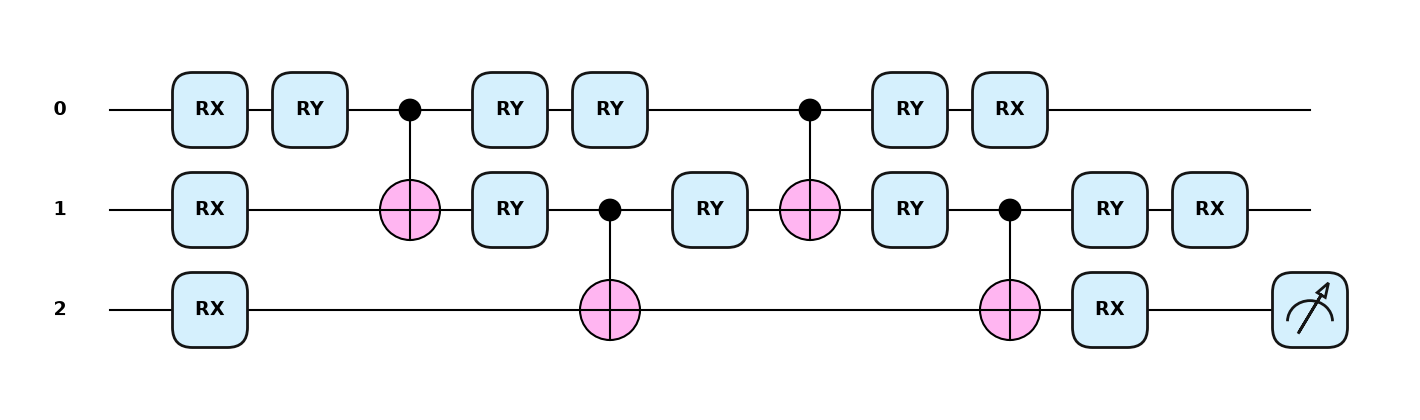

5 trainable parameters, 6 RX gates carrying x, 4 CNOTs, 8 RY gates


In [4]:
dev = qml.device("default.qubit", wires=n_qubits)
n_params = (n_qubits - 1) * n_layers + 1


def feature_map(x):
    """Encode x as an RX rotation on every qubit."""
    for w in range(n_qubits):
        qml.RX(x, wires=w)


def variational_ansatz(theta):
    """Each layer interleaves RY - CNOT - RY on every adjacent pair of qubits."""
    idx = 0
    for _ in range(n_layers):
        for w in range(n_qubits - 1):
            qml.RY(theta[idx], wires=w)
            qml.CNOT(wires=[w, w + 1])
            qml.RY(theta[idx + 1], wires=w)
            idx += 1


def dqc_body(x, theta):
    feature_map(x)
    variational_ansatz(theta)
    feature_map(x)            # data re-uploading


@qml.qnode(dev)
def circuit(x, theta):
    dqc_body(x, theta)
    return qml.expval(qml.PauliZ(2))


theta_demo = onp.random.default_rng(0).uniform(0, 2 * onp.pi, n_params)
fig, ax = qml.draw_mpl(circuit, style="pennylane")(0.6, theta_demo)
plt.show()
print(f"{n_params} trainable parameters, {2 * n_qubits} RX gates carrying x, {(n_qubits - 1) * n_layers} CNOTs, {2 * (n_qubits - 1) * n_layers} RY gates")

### 1.2 Why encode $x$ twice

A circuit whose only $x$-dependence comes from $R_X(x)$ gates computes a **Fourier series** in $x$. The frequencies it can contain are fixed by the encoding gates, not by training ([Schuld, Sweke and Meyer, 2021](https://arxiv.org/abs/2008.08605)). One layer of $R_X(x)$ on 3 qubits reaches integer frequencies up to 3; encoding twice reaches up to 6.

Our target $\cos(2x)$ has frequency 2. Let's measure how much spectral power each design puts there, averaged over random parameters.

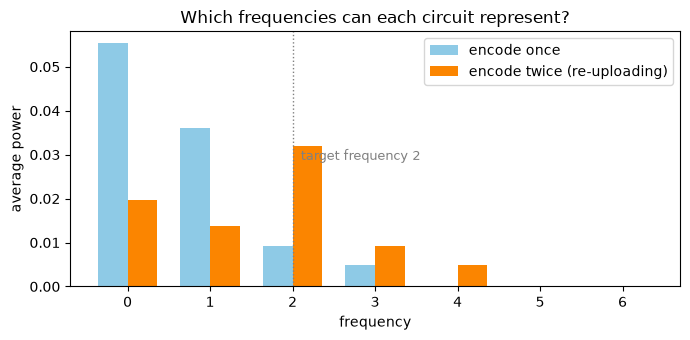

power at frequency 2: once = 0.0093, twice = 0.0320  (3.5x)
power at frequency 4: once = 2.9e-34 (unreachable), twice = 0.0049


In [5]:
@qml.qnode(dev)
def circuit_single_upload(x, theta):
    feature_map(x)
    variational_ansatz(theta)
    return qml.expval(qml.PauliZ(2))


def average_power(circuit_fn, n_draws=25, n_samples=128, seed=0):
    rng = onp.random.default_rng(seed)
    xs = onp.linspace(0, 2 * onp.pi, n_samples, endpoint=False)
    power = onp.zeros(n_samples)
    for _ in range(n_draws):
        th = rng.uniform(0, 2 * onp.pi, n_params)
        ys = onp.array([float(circuit_fn(x, th)) for x in xs])
        power += onp.abs(onp.fft.fft(ys) / n_samples) ** 2
    return power / n_draws


p_single, p_double = average_power(circuit_single_upload), average_power(circuit)
freqs = onp.arange(0, 7)
plt.figure(figsize=(7, 3.5))
plt.bar(freqs - 0.18, [p_single[k] for k in freqs], 0.36, label="encode once", color="#8ecae6")
plt.bar(freqs + 0.18, [p_double[k] for k in freqs], 0.36, label="encode twice (re-uploading)", color="#fb8500")
plt.axvline(2, color="gray", ls=":", lw=1)
plt.text(2.1, max(p_double[1:7]) * 0.9, "target frequency 2", color="gray", fontsize=9)
plt.xlabel("frequency"); plt.ylabel("average power"); plt.legend(); plt.title("Which frequencies can each circuit represent?")
plt.tight_layout(); plt.show()
print(f"power at frequency 2: once = {p_single[2]:.4f}, twice = {p_double[2]:.4f}  ({p_double[2] / p_single[2]:.1f}x)")
print(f"power at frequency 4: once = {p_single[4]:.1e} (unreachable), twice = {p_double[4]:.4f}")

Encoding once leaves frequency 4 at exactly zero for any $\theta$, and puts little power at frequency 2. Re-uploading opens higher frequencies and puts more weight where $\cos(2x)$ lives. This is an architectural limit fixed before training starts, which is why the first design choice of a variational algorithm matters so much.

### 1.3 Optimize: derivatives, loss, training

The loss needs $y'(x)$ and $y''(x)$. PennyLane differentiates the circuit **exactly** with respect to $x$; on hardware the same derivatives come from the parameter-shift rule, which only needs extra circuit runs at shifted angles (we will count them in Chapter 5).

The loss is the squared ODE residual at 8 collocation points plus the two boundary conditions, weighted by 10:

$$\mathcal{L}(\theta) = \frac{1}{8}\sum_{i=1}^{8}\big(y''_\theta(x_i) + \omega^2 y_\theta(x_i)\big)^2 + 10\Big[\big(y_\theta(0)-1\big)^2 + \big(y'_\theta(0)\big)^2\Big].$$

In [6]:
def dy_dx(x, theta):
    return qml.grad(circuit, argnums=0)(x, theta)


def d2y_dx2(x, theta):
    return qml.grad(lambda xx, tt: qml.grad(circuit, argnums=0)(xx, tt), argnums=0)(x, theta)


def loss_fn(theta, x_colloc):
    residual = sum((d2y_dx2(x, theta) + omega**2 * circuit(x, theta)) ** 2 for x in x_colloc) / len(x_colloc)
    boundary = (circuit(0.0, theta) - 1.0) ** 2 + dy_dx(0.0, theta) ** 2
    return residual + 10.0 * boundary


onp.random.seed(0)
theta = np.array(onp.random.uniform(0, 2 * onp.pi, n_params), requires_grad=True)
x_colloc = np.linspace(0.0, 1.5, 8)       # requires_grad=True: we differentiate with respect to x
opt = qml.AdamOptimizer(stepsize=0.1)

history = []
for it in range(150):
    theta, cost = opt.step_and_cost(lambda t: loss_fn(t, x_colloc), theta)
    history.append(float(cost))
    if it % 25 == 0:
        print(f"iteration {it:3d}   loss = {float(cost):.6f}")

theta_opt = np.array(theta, requires_grad=False)
print(f"final loss = {float(loss_fn(theta_opt, x_colloc)):.2e}")

iteration   0   loss = 13.393341


iteration  25   loss = 2.085542


iteration  50   loss = 0.027460


iteration  75   loss = 0.005280


iteration 100   loss = 0.000677


iteration 125   loss = 0.000147


final loss = 5.08e-05


### 1.4 Analyze: did it learn $\cos(2x)$?

  x     DQC (ideal)   cos(2x)    |error|
0.00     0.99779     1.00000    2.2e-03
0.25     0.87561     0.87758    2.0e-03
0.50     0.53902     0.54030    1.3e-03
0.75     0.07049     0.07074    2.4e-04
1.00    -0.41523    -0.41615    9.2e-04
1.25    -0.79929    -0.80114    1.9e-03
1.50    -0.98776    -0.98999    2.2e-03

max |error| of the trained model, no noise: 2.2e-03


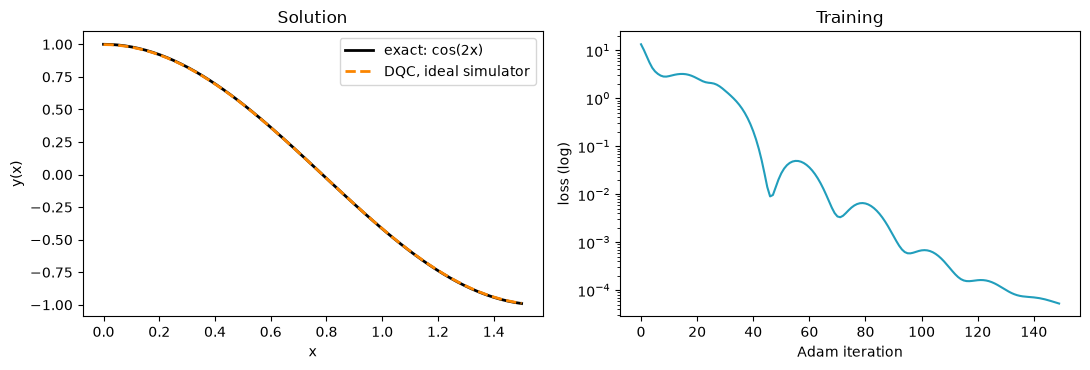

In [7]:
xs_eval = onp.linspace(0, 1.5, 7)
y_ideal = onp.array([float(circuit(x, theta_opt)) for x in xs_eval])
y_exact = onp.cos(omega * xs_eval)

print("  x     DQC (ideal)   cos(2x)    |error|")
for x, yi, ye in zip(xs_eval, y_ideal, y_exact):
    print(f"{x:4.2f}    {yi: .5f}    {ye: .5f}    {abs(yi - ye):.1e}")
print(f"\nmax |error| of the trained model, no noise: {onp.max(onp.abs(y_ideal - y_exact)):.1e}")

xs_fine = onp.linspace(0, 1.5, 60)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(xs_fine, onp.cos(omega * xs_fine), "k-", lw=2, label="exact: cos(2x)")
ax[0].plot(xs_fine, [float(circuit(x, theta_opt)) for x in xs_fine], "--", color="#fb8500", lw=2, label="DQC, ideal simulator")
ax[0].set_xlabel("x"); ax[0].set_ylabel("y(x)"); ax[0].legend(); ax[0].set_title("Solution")
ax[1].semilogy(history, color="#219ebc"); ax[1].set_xlabel("Adam iteration"); ax[1].set_ylabel("loss (log)"); ax[1].set_title("Training")
plt.tight_layout(); plt.show()

The circuit was never told what a cosine is; it only saw the equation and the boundary conditions. The remaining error, about $2\times10^{-3}$ at the edges, is the **model error**: what training could not remove. Keep it in mind, because every noise effect in the next chapters is measured against the ideal circuit, not against $\cos(2x)$, so we can separate hardware error from model error.

<div class="alert alert-block alert-info">
<b>Check your understanding.</b> If you encoded $x$ only once, could more training iterations make the circuit represent $\cos(4x)$?
<details><summary>Show the answer</summary>

No. With one layer of $R_X(x)$ on 3 qubits, frequency 4 has exactly zero power for every $\theta$ (Section 1.2). Training changes Fourier coefficients, never which frequencies exist.

</details>
</div>

### Chapter 1 summary

- **Map:** $y(x) = \langle Z_2 \rangle$ of a 3-qubit circuit: feature map, ansatz, feature map again.
- **Optimize:** the ODE residual is the loss; exact derivatives in $x$ come from the circuit itself.
- **Analyze:** max error against $\cos(2x)$ is about $2\times10^{-3}$ with no noise. That is our ceiling.

# Chapter 2 — Noise: what real hardware does to the answer

Lab 2 introduced three toy noise models: **depolarization** (isotropic gate imperfection), **Pauli errors** (directional $X/Y/Z$ flips), and **thermal relaxation** (time-dependent decay set by $T_1$ and $T_2$), plus **readout error**. Here we stop treating them as toys: we take their strengths from a real calibration snapshot and apply them to our trained circuit.

### 2.1 Backend information

`FakeMarrakesh` is an offline snapshot of a 156-qubit IBM Heron processor: real gate errors, coherence times, and readout errors, with no account or network involved. Physical qubits 0, 1, 2 are connected as 0–1 and 1–2, exactly the chain our ansatz uses, so no SWAP gates are needed.

In [8]:
backend = FakeMarrakesh()
target = backend.target
qubits = [0, 1, 2]

sx_err = {q: target["sx"][(q,)].error for q in qubits}
cz_err = {(0, 1): target["cz"][(0, 1)].error, (1, 2): target["cz"][(1, 2)].error}
readout_err = {q: target["measure"][(q,)].error for q in qubits}
T1 = {q: backend.qubit_properties(q).t1 for q in qubits}
T2 = {q: backend.qubit_properties(q).t2 for q in qubits}
sx_dur, cz_dur = target["sx"][(0,)].duration, target["cz"][(0, 1)].duration

print(f"{'qubit':>5} {'sx error':>10} {'readout':>9} {'T1 (us)':>9} {'T2 (us)':>9}")
for q in qubits:
    print(f"{q:>5} {sx_err[q]:>10.2e} {readout_err[q]:>9.2%} {T1[q]*1e6:>9.1f} {T2[q]*1e6:>9.1f}")
for pair, e in cz_err.items():
    print(f"cz {pair}: error {e:.2e}, duration {cz_dur*1e9:.0f} ns")
print(f"sx duration {sx_dur*1e9:.0f} ns")

qubit   sx error   readout   T1 (us)   T2 (us)
    0   1.35e-04     1.12%     365.6      61.4
    1   1.03e-04     0.54%     182.8     187.2
    2   2.05e-04     0.42%     276.8     330.3
cz (0, 1): error 1.74e-03, duration 68 ns
cz (1, 2): error 1.55e-03, duration 68 ns
sx duration 36 ns


Two things stand out before running anything:

- **Nothing is uniform.** Qubit 0's readout error is almost 3 times qubit 2's.
- **Qubit 0 dephases fast.** Its $T_2$ (about 61 µs) is much shorter than its $T_1$ (about 366 µs), so phase information decays faster than energy. A single "error rate $p$" would hide this.

### 2.2 A backend-informed noise model

We attach noise to each gate of the PennyLane circuit, using the numbers above:

| Noise | Where it acts | Strength | Lab 2 toy model |
|---|---|---|---|
| Depolarizing | after each rotation | 2 × sx error (a rotation compiles to about 2 `sx` pulses) | depolarization |
| Depolarizing | on both qubits after each CNOT | CZ error of that pair | depolarization |
| Thermal relaxation | during each gate | the qubit's $T_1$, $T_2$ over the gate duration | thermal relaxation |
| Readout bit flip | on qubit 2, at measurement | readout error of qubit 2 | Pauli $X$ error |

We simulate with `default.mixed` (density matrices), so every expectation value is **exact**, with no shot noise. That lets us see small effects clearly. Readout error is applied as a final factor, since for a symmetric bit flip of probability $p$:

$$\langle Z\rangle_{\text{measured}} = (1-2p)\,\langle Z\rangle_{\text{before readout}} .$$

The `scale` argument multiplies every error rate; Chapter 3 uses it to check ZNE's assumptions.

In [9]:
rot_dur = 2 * sx_dur                 # one arbitrary rotation ~ 2 sx pulses (plus virtual rz)
cnot_dur = cz_dur + 2 * sx_dur       # CNOT = H . CZ . H on the target


def make_noise_model(gates=True, decoherence=True, scale=1.0):
    def after_rotation(op, **kwargs):
        w = op.wires[0]
        if gates:
            qml.DepolarizingChannel(min(2 * sx_err[w] * scale, 0.75), wires=w)
        if decoherence:
            qml.ThermalRelaxationError(0.0, T1[w] / scale, min(T2[w], 2 * T1[w]) / scale, rot_dur, wires=w)

    def after_cnot(op, **kwargs):
        a, b = op.wires
        p = min(cz_err[(min(a, b), max(a, b))] * scale, 0.75)
        for w in (a, b):
            if gates:
                qml.DepolarizingChannel(p, wires=w)
            if decoherence:
                qml.ThermalRelaxationError(0.0, T1[w] / scale, min(T2[w], 2 * T1[w]) / scale, cnot_dur, wires=w)

    return qml.NoiseModel({qml.noise.op_in(["RX", "RY"]): after_rotation,
                           qml.noise.op_eq("CNOT"): after_cnot})


dev_mixed = qml.device("default.mixed", wires=n_qubits)


def noisy_circuit(gates=True, decoherence=True, scale=1.0):
    """QNode with gate + decoherence noise; readout is applied separately."""
    @qml.qnode(qml.add_noise(dev_mixed, make_noise_model(gates, decoherence, scale)))
    def f(x, theta):
        dqc_body(x, theta)
        return qml.expval(qml.PauliZ(2))
    return f


def with_readout(value, p=None):
    p = readout_err[2] if p is None else p
    return (1 - 2 * p) * value


noisy = noisy_circuit()

### 2.3 Ideal versus noisy

  x     ideal      noisy     |noisy - ideal|
0.00   0.99779    0.97677     2.1e-02
0.25   0.87561    0.85725     1.8e-02
0.50   0.53902    0.52799     1.1e-02
0.75   0.07049    0.06966     8.3e-04
1.00  -0.41523   -0.40553     9.7e-03
1.25  -0.79929   -0.78132     1.8e-02
1.50  -0.98776   -0.96584     2.2e-02

max hardware error: 2.2e-02   (model error was 2.2e-03)


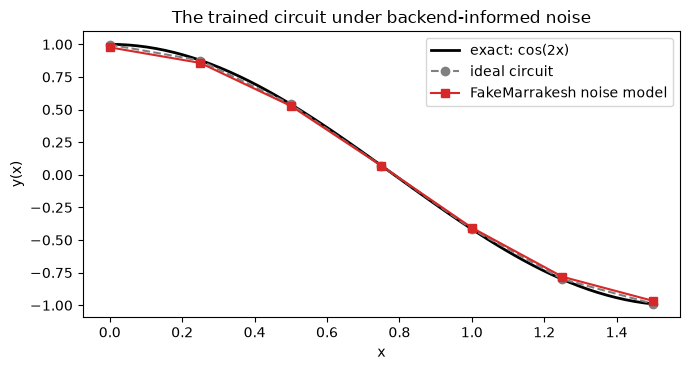

In [10]:
y_noisy = onp.array([with_readout(float(noisy(x, theta_opt))) for x in xs_eval])

print("  x     ideal      noisy     |noisy - ideal|")
for x, yi, yn in zip(xs_eval, y_ideal, y_noisy):
    print(f"{x:4.2f}  {yi: .5f}   {yn: .5f}     {abs(yn - yi):.1e}")
print(f"\nmax hardware error: {onp.max(onp.abs(y_noisy - y_ideal)):.1e}   "
      f"(model error was {onp.max(onp.abs(y_ideal - y_exact)):.1e})")

plt.figure(figsize=(7, 3.8))
plt.plot(xs_fine, onp.cos(omega * xs_fine), "k-", lw=2, label="exact: cos(2x)")
plt.plot(xs_eval, y_ideal, "o--", color="gray", label="ideal circuit")
plt.plot(xs_eval, y_noisy, "s-", color="#d62828", label="FakeMarrakesh noise model")
plt.xlabel("x"); plt.ylabel("y(x)"); plt.legend(); plt.title("The trained circuit under backend-informed noise")
plt.tight_layout(); plt.show()

Noise pulls every value **toward zero**. That is the signature of depolarization and readout error: both shrink $\langle Z\rangle$ by a factor slightly below 1. The hardware error is about 10 times the model error, so on this device **noise, not training, limits the accuracy**.

### 2.4 Error budget: which source dominates?

Because the simulation is exact, we can switch on one noise source at a time and measure its contribution. This is the most useful single analysis before choosing a mitigation strategy.

gate errors            shift  0.00999   (45.6% of total)
decoherence (T1/T2)    shift  0.00388   (17.7% of total)
readout                shift  0.00820   (37.4% of total)
all together           shift  0.02192


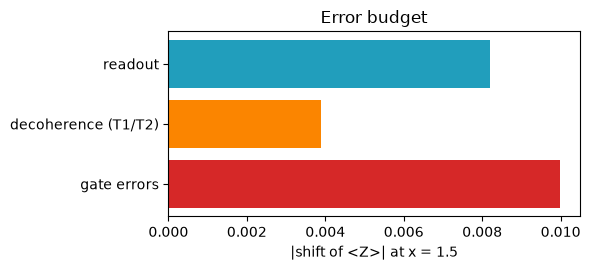

In [11]:
x_probe = 1.5     # an x where the error is large
ideal_probe = float(circuit(x_probe, theta_opt))
budget = {
    "gate errors": float(noisy_circuit(gates=True, decoherence=False)(x_probe, theta_opt)) - ideal_probe,
    "decoherence (T1/T2)": float(noisy_circuit(gates=False, decoherence=True)(x_probe, theta_opt)) - ideal_probe,
    "readout": with_readout(ideal_probe) - ideal_probe,
}
total = with_readout(float(noisy(x_probe, theta_opt))) - ideal_probe
for name, shift in budget.items():
    print(f"{name:<22s} shift {shift: .5f}   ({abs(shift) / abs(total):5.1%} of total)")
print(f"{'all together':<22s} shift {total: .5f}")

plt.figure(figsize=(6, 2.8))
plt.barh(list(budget), [abs(v) for v in budget.values()], color=["#d62828", "#fb8500", "#219ebc"])
plt.xlabel(f"|shift of <Z>| at x = {x_probe}"); plt.title("Error budget")
plt.tight_layout(); plt.show()

**Gate errors are the largest share (about 46%), readout is close behind (about 37%), and decoherence is the smallest (about 18%).** The circuit is short (4 CNOTs, well under 1 µs), so $T_1$ and $T_2$ matter less than the gates themselves. The three shares add up to the total, because at these small error rates the sources barely interact.

That split decides the strategy in Chapter 3. Gate errors and decoherence both happen *inside* the circuit; readout error happens once, *after* it. A technique that only acts inside the circuit can remove at most about 63% of the error.

### 2.5 Cross-check with Qiskit Aer

Our noise model was built by hand. Is it realistic? We cross-check it against `AerSimulator.from_backend(FakeMarrakesh())`, which builds its own noise model from the same calibration data, following the Qiskit pattern from Lab 2:

1. **Map:** write the same trained circuit in Qiskit.
2. **Optimize:** transpile it to the backend's native gates (`cz`, `rz`, `sx`, `x`) on physical qubits 0, 1, 2.
3. **Execute:** run it on the noisy simulator with many shots.
4. **Analyze:** compare $\langle Z_2 \rangle$ with our PennyLane model.

In [12]:
theta_np = onp.array(theta_opt)


def dqc_qiskit(x, th):
    qc = QuantumCircuit(n_qubits)
    for w in range(n_qubits):
        qc.rx(x, w)
    idx = 0
    for _ in range(n_layers):
        for w in range(n_qubits - 1):
            qc.ry(th[idx], w); qc.cx(w, w + 1); qc.ry(th[idx + 1], w)
            idx += 1
    for w in range(n_qubits):
        qc.rx(x, w)
    return qc


def measure_logical_qubit(circ, layout, logical=2):
    """Measure the physical qubit that holds logical qubit `logical` after transpilation."""
    phys = layout.final_index_layout()[logical]
    m = QuantumCircuit(circ.num_qubits, 1)
    m.compose(circ, inplace=True)
    m.measure(phys, 0)
    return m


x_test, shots = 0.6, 200_000
isa = transpile(dqc_qiskit(x_test, theta_np), backend, initial_layout=qubits, optimization_level=1, seed_transpiler=7)
print("ISA circuit:", dict(isa.count_ops()), "| depth", isa.depth())

aer_noisy = AerSimulator.from_backend(backend, seed_simulator=7)
z_aer = expval_z_from_counts(aer_noisy.run(measure_logical_qubit(isa, isa.layout), shots=shots).result().get_counts())
z_model = with_readout(float(noisy(x_test, theta_opt)))
z_ideal = float(circuit(x_test, theta_opt))
shot_std = onp.sqrt((1 - z_aer**2) / shots)

report("ideal circuit", z_ideal, z_ideal)
report("PennyLane noise model (exact)", z_model, z_ideal)
report("Aer + FakeMarrakesh (200k shots)", z_aer, z_ideal)
print(f"\nshot-noise standard deviation of the Aer value: {shot_std:.4f}")

ISA circuit: {'rz': 20, 'sx': 17, 'cz': 4} | depth 23


ideal circuit                       0.36146   (reference  0.36146, |error| = 0.00e+00)
PennyLane noise model (exact)       0.35430   (reference  0.36146, |error| = 7.16e-03)
Aer + FakeMarrakesh (200k shots)    0.35834   (reference  0.36146, |error| = 3.12e-03)

shot-noise standard deviation of the Aer value: 0.0021


Both noisy values land below the ideal one, in the same direction and with the same order of magnitude, but Aer's shift is about half of ours. The reason is visible in the ISA circuit: the transpiler merges adjacent rotations, so the real circuit has 17 `sx` pulses, while our model charges 2 pulses per rotation plus 2 per CNOT, about 36. **Our model is deliberately pessimistic**, which is the safe direction for the analyses in the next chapters; the conclusions hold for both.

Note the size of the shot noise: about $2\times10^{-3}$ even with 200,000 shots, comparable to the noise bias we want to remove. We return to this in Section 3.5.

<div class="alert alert-block alert-info">
<b>Check your understanding.</b> Our circuit has 4 CNOTs and runs in under 1 µs. Would decoherence matter more for a 100-layer ansatz?
<details><summary>Show the answer</summary>

Yes. Decoherence grows with total circuit duration, while readout error is paid once at the end. In a deep circuit, decoherence and gate errors dominate and readout becomes the small term, so the error budget (Section 2.4) must be recomputed for every circuit and device.

</details>
</div>

### Chapter 2 summary

- Calibration data is **not uniform**: readout and $T_2$ vary several-fold between neighbouring qubits.
- Noise shrinks the answer toward zero; the hardware error is about **10×** the model error.
- **Error budget at $x = 1.5$:** gate errors ≈ 46%, readout ≈ 37%, decoherence ≈ 18%.
- An independent Qiskit Aer simulation agrees in direction and order of magnitude; our model is about 2× more pessimistic, because the transpiler merges rotations.

# Chapter 3 — Quantum error mitigation (QEM)

Error mitigation does **not** fix errors inside a run. It runs extra circuits and uses classical post-processing to estimate what the noiseless expectation value would have been. It needs no extra qubits, which makes it the natural first tool on today's hardware.

### 3.1 Zero-noise extrapolation (ZNE)

ZNE has two steps:

1. **Amplify the noise on purpose** by a known factor $\lambda$. *Global folding* replaces the circuit $U$ with $U\,(U^\dagger U)^{k}$: logically the same circuit, physically $\lambda = 2k+1$ times more gates, and so about $\lambda$ times more gate noise.
2. **Measure** $E(\lambda)$ at $\lambda = 1, 3, 5$ and **extrapolate** to $\lambda = 0$.

With three points, Richardson extrapolation fits the unique quadratic through them:

$$E(0) \approx \sum_i \gamma_i\,E(\lambda_i), \qquad \gamma_i = \prod_{j\neq i} \frac{\lambda_j}{\lambda_j - \lambda_i}.$$

In [13]:
gate_noisy = noisy_circuit()            # gate + decoherence noise; readout handled separately
scales = [1, 3, 5]
folded = {s: qml.noise.fold_global(gate_noisy, scale_factor=s) for s in scales}

for s in scales:
    tape = qml.workflow.construct_tape(folded[s])(x_test, theta_opt)
    print(f"scale {s}: {len(tape.operations)} gates")

# does folding really scale the noise? compare with multiplying every error rate by s
print("\nscale   folded circuit   noise model x scale")
for s in scales:
    print(f"{s:>5}   {float(folded[s](x_test, theta_opt)): .5f}         {float(noisy_circuit(scale=s)(x_test, theta_opt)): .5f}")

scale 1: 18 gates
scale 3: 54 gates
scale 5: 90 gates

scale   folded circuit   noise model x scale
    1    0.35726          0.35726
    3    0.34890          0.34906
    5    0.34078          0.34109


Folding and directly multiplying the error rates agree to about $3\times10^{-4}$: for this circuit, folding is a faithful noise amplifier, which is the assumption ZNE relies on.

Now the extrapolation itself, at $x = 0.6$, including readout error as a real measurement would:

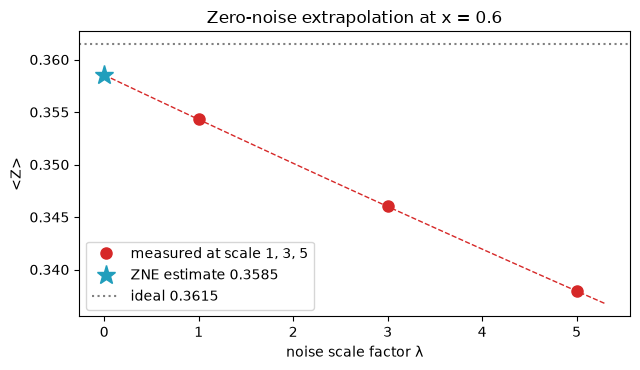

raw (scale 1)                       0.35430   (reference  0.36146, |error| = 7.16e-03)
ZNE (Richardson)                    0.35853   (reference  0.36146, |error| = 2.92e-03)


In [14]:
def measured(s, x):
    """What a device reports at noise scale s: folded gate noise, then readout (readout is never folded)."""
    return with_readout(float(folded[s](x, theta_opt)))


vals = [measured(s, x_test) for s in scales]
zne_value = float(qml.noise.richardson_extrapolate(scales, vals))

lam = onp.linspace(0, 5.3, 100)
coef = onp.polyfit(scales, vals, 2)
plt.figure(figsize=(6.5, 3.8))
plt.plot(scales, vals, "o", color="#d62828", ms=8, label="measured at scale 1, 3, 5")
plt.plot(lam, onp.polyval(coef, lam), "--", color="#d62828", lw=1)
plt.plot([0], [zne_value], "*", color="#219ebc", ms=14, label=f"ZNE estimate {zne_value:.4f}")
plt.axhline(z_ideal, color="gray", ls=":", label=f"ideal {z_ideal:.4f}")
plt.xlabel("noise scale factor λ"); plt.ylabel("<Z>"); plt.legend(); plt.title("Zero-noise extrapolation at x = 0.6")
plt.tight_layout(); plt.show()

report("raw (scale 1)", vals[0], z_ideal)
report("ZNE (Richardson)", zne_value, z_ideal)

### 3.2 What ZNE cannot see

ZNE improved the answer, but did not reach the ideal value. Let's look across the whole range of $x$.

In [15]:
raw_err, zne_err = [], []
print("  x     raw err    ZNE err   removed")
for x in xs_eval:
    ideal_x = float(circuit(x, theta_opt))
    v = [measured(s, x) for s in scales]
    raw_err.append(abs(v[0] - ideal_x))
    zne_err.append(abs(float(qml.noise.richardson_extrapolate(scales, v)) - ideal_x))
    print(f"{x:4.2f}   {raw_err[-1]:.1e}    {zne_err[-1]:.1e}    {1 - zne_err[-1] / raw_err[-1]:5.0%}")

  x     raw err    ZNE err   removed
0.00   2.1e-02    8.3e-03      61%


0.25   1.8e-02    7.3e-03      60%
0.50   1.1e-02    4.4e-03      60%
0.75   8.3e-04    4.7e-04      44%


1.00   9.7e-03    3.6e-03      63%
1.25   1.8e-02    6.9e-03      62%
1.50   2.2e-02    8.5e-03      61%


ZNE removes about **60%** of the error at almost every point. The remaining 40% is the readout error from the budget in Section 2.4 (at $x = 0.75$ the circuit output is close to 0, where every multiplicative error is tiny, so the percentages there are less meaningful). Folding repeats gates; it does not repeat the measurement, so the readout error is **the same at every scale** and the extrapolation cannot see it.

This is the most common way ZNE disappoints in practice: it is applied to an error source it was never designed to address.

### 3.3 Stacking readout mitigation and ZNE

Readout error has its own, cheap mitigation. Measure the readout error rate $p$ by preparing $|0\rangle$ and $|1\rangle$ (a calibration you get from the backend for free), then invert the bit flip:

$$\langle Z\rangle_{\text{corrected}} = \frac{\langle Z\rangle_{\text{measured}}}{1 - 2p}.$$

For several qubits the same idea becomes inverting a confusion matrix (the M3 and TREX methods). We apply it to each scale, then extrapolate.

method            mean |error|  max |error|  circuits
raw                    1.4e-02      2.2e-02         1
readout only           8.9e-03      1.4e-02         1
ZNE only               5.6e-03      8.5e-03         3
readout + ZNE          1.2e-04      2.7e-04         3


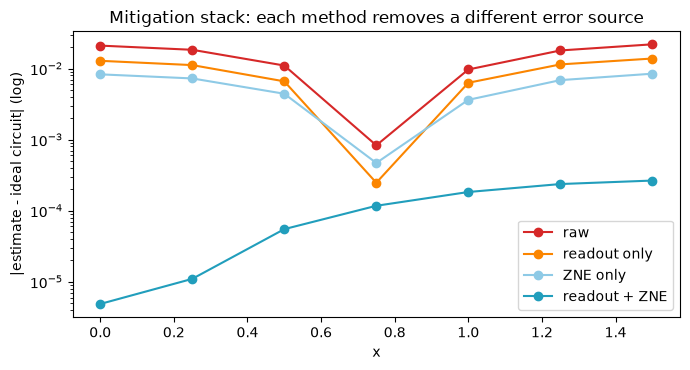

In [16]:
results = {"raw": [], "readout only": [], "ZNE only": [], "readout + ZNE": []}
for x in xs_eval:
    ideal_x = float(circuit(x, theta_opt))
    v = [measured(s, x) for s in scales]
    v_ro = [vi / (1 - 2 * readout_err[2]) for vi in v]
    estimates = {
        "raw": v[0],
        "readout only": v_ro[0],
        "ZNE only": float(qml.noise.richardson_extrapolate(scales, v)),
        "readout + ZNE": float(qml.noise.richardson_extrapolate(scales, v_ro)),
    }
    for k, e in estimates.items():
        results[k].append(abs(e - ideal_x))

print(f"{'method':<16s} {'mean |error|':>13s} {'max |error|':>12s} {'circuits':>9s}")
cost = {"raw": 1, "readout only": 1, "ZNE only": 3, "readout + ZNE": 3}
for k, errs in results.items():
    print(f"{k:<16s} {onp.mean(errs):>13.1e} {onp.max(errs):>12.1e} {cost[k]:>9d}")

plt.figure(figsize=(7, 3.8))
for (k, errs), c in zip(results.items(), ["#d62828", "#fb8500", "#8ecae6", "#219ebc"]):
    plt.semilogy(xs_eval, errs, "o-", color=c, label=k)
plt.xlabel("x"); plt.ylabel("|estimate - ideal circuit| (log)"); plt.legend()
plt.title("Mitigation stack: each method removes a different error source")
plt.tight_layout(); plt.show()

Each method removes **one** source. Readout mitigation alone and ZNE alone each leave the other source behind; together they cut the error by about **two orders of magnitude**, close to the ideal circuit, for 3 circuits instead of 1 and no extra qubits.

The general lesson: **build the error budget first, then match one mitigation to each source.**

### 3.4 ZNE in Qiskit, and the folding trap

On real hardware, folding must happen on the **transpiled (ISA) circuit**, so the folded gates are the gates that actually run. Here is the same experiment with Qiskit Aer and `FakeMarrakesh`.

In [17]:
def fold_isa(isa, scale):
    """Global folding of a transpiled circuit: U (U^dagger U)^((scale-1)/2).
    Barriers stop any later compiler pass from cancelling U^dagger U."""
    u = isa.copy()
    # the inverse contains sxdg, which is not a native gate: translate it without optimizing
    u_inv = transpile(u.inverse(), basis_gates=["rz", "sx", "x", "cz"], optimization_level=0)
    out = u.copy()
    for _ in range((scale - 1) // 2):
        out.barrier(); out = out.compose(u_inv)
        out.barrier(); out = out.compose(u)
    return out


aer_vals = []
for s in scales:
    circ = measure_logical_qubit(fold_isa(isa, s), isa.layout)
    aer_vals.append(expval_z_from_counts(aer_noisy.run(circ, shots=shots).result().get_counts()))
    print(f"scale {s}: {circ.count_ops().get('cz', 0):>2d} CZ gates, <Z> = {aer_vals[-1]: .5f}")

aer_ro = [v / (1 - 2 * readout_err[2]) for v in aer_vals]
report("Aer raw", aer_vals[0], z_ideal)
report("Aer readout + ZNE", float(qml.noise.richardson_extrapolate(scales, aer_ro)), z_ideal)

scale 1:  4 CZ gates, <Z> =  0.35834


scale 3: 12 CZ gates, <Z> =  0.35334


scale 5: 20 CZ gates, <Z> =  0.34835
Aer raw                             0.35834   (reference  0.36146, |error| = 3.12e-03)
Aer readout + ZNE                   0.36386   (reference  0.36146, |error| = 2.41e-03)


Folding behaves as expected: the noise-scaled values fall by about $5\times10^{-3}$ per fold. The mitigated estimate, however, **overshoots** the ideal value, and its error is barely smaller than the raw one. That is not a failure of the method: with 200,000 shots per scale, the ZNE estimate has a shot-noise standard deviation of about $2.3 \times 0.0021 \approx 5\times10^{-3}$, larger than the bias we are trying to remove. Section 3.5 turns this into a number.

**The trap.** Fold the *logical* circuit without barriers and transpile it afterwards, as one naturally would:

In [18]:
qc = dqc_qiskit(x_test, theta_np)
folded_no_barriers = qc.compose(qc.inverse()).compose(qc)       # logically U U^dagger U = U
for level in (0, 1, 3):
    t = transpile(folded_no_barriers, backend, initial_layout=qubits, optimization_level=level, seed_transpiler=7)
    print(f"optimization_level={level}: {t.count_ops().get('cz', 0):>2d} CZ gates (scale 1 has {isa.count_ops().get('cz', 0)})")

optimization_level=0: 12 CZ gates (scale 1 has 4)
optimization_level=1:  4 CZ gates (scale 1 has 4)
optimization_level=3:  4 CZ gates (scale 1 has 4)


At `optimization_level=1` and above, the transpiler recognizes $U^\dagger U$ as the identity and removes it: the "scale 3" circuit silently becomes the scale-1 circuit. ZNE would then extrapolate from three measurements of the same noise level, and nothing in the output would warn you. **Fold after transpilation, and protect the folds with barriers.**

### 3.5 The price: sampling overhead

Mitigation is not free; it pays in **shots**. The ZNE estimate is a weighted sum of measured values, so its shot-noise variance is the sum of the weighted variances:

$$\sigma_{\text{ZNE}} = \sqrt{\sum_i \gamma_i^2}\;\sigma_{\text{single}} .$$

In [19]:
lam_arr = onp.array(scales, dtype=float)
gammas = [onp.prod([lam_arr[j] / (lam_arr[j] - lam_arr[i]) for j in range(3) if j != i]) for i in range(3)]
amplification = onp.sqrt(onp.sum(onp.square(gammas)))
print("Richardson weights:", [f"{g:+.3f}" for g in gammas], "| sum =", f"{sum(gammas):.3f}")
print(f"shot-noise amplification: {amplification:.2f}x  ->  {amplification**2:.1f}x more shots per scale for the same precision")

# how many shots until the mitigated estimate beats the raw one at x = 0.6?
bias_raw = abs(with_readout(float(noisy(x_test, theta_opt))) - z_ideal)
target_std = bias_raw / 3                 # resolve the bias at 3 standard deviations
spread = onp.sqrt(1 - z_ideal**2)         # single-shot standard deviation of a +/-1 outcome
shots_needed = (amplification * spread / target_std) ** 2
print(f"\nraw bias at x = {x_test}: {bias_raw:.1e}")
print(f"shots per scale to resolve it at 3 sigma: {shots_needed:,.0f}  (x 3 scales = {3 * shots_needed:,.0f} shots for ONE value of y(x))")

Richardson weights: ['+1.875', '-1.250', '+0.375'] | sum = 1.000
shot-noise amplification: 2.28x  ->  5.2x more shots per scale for the same precision

raw bias at x = 0.6: 7.2e-03
shots per scale to resolve it at 3 sigma: 797,004  (x 3 scales = 2,391,011 shots for ONE value of y(x))


This is the real limit of mitigation on a good device. The noise bias is already small, so detecting and removing it takes a large number of shots for **one** point of the solution. Mitigation trades bias for variance: the better the hardware, the more shots it takes to see the improvement.

<div class="alert alert-block alert-info">
<b>Check your understanding.</b> Why is the sum of the Richardson weights exactly 1?
<details><summary>Show the answer</summary>

If every measurement returned the same value $E$ (no noise dependence), the extrapolation must return $E$. That only happens if $\sum_i \gamma_i = 1$. The negative weight is what amplifies shot noise.

</details>
</div>

### Chapter 3 summary

- **ZNE** amplifies gate noise by folding and extrapolates to zero noise. Alone, it removed about 60% of the error here.
- ZNE **cannot see readout error**. Readout mitigation plus ZNE removed about two orders of magnitude.
- Fold **after** transpiling and protect the folds with **barriers**, or the compiler deletes them.
- The cost is **shots**: about 5× more per scale for the same precision, and large shot counts once the hardware is already good.

# Chapter 4 — Quantum error correction (QEC)

QEC is the only route to arbitrarily long computations. It encodes one logical qubit in many physical qubits, measures **stabilizers** to detect errors without measuring the logical state, and corrects them. Two numbers govern it:

- **Code distance $d$:** the fewest physical errors that cause an undetected logical error. A distance-$d$ code corrects $\lfloor (d-1)/2 \rfloor$ errors.
- **Threshold $p_{th}$:** below it, increasing $d$ suppresses logical errors exponentially; above it, more qubits make things worse.

In this chapter we compute where those thresholds sit and what they imply for our ODE solver.

### 4.1 Threshold, exactly: the repetition code

A distance-$d$ repetition code with majority vote fails when more than half of its qubits flip:

$$P_L(d,p) = \sum_{k=\lceil (d+1)/2\rceil}^{d} \binom{d}{k}\,p^k(1-p)^{d-k}.$$

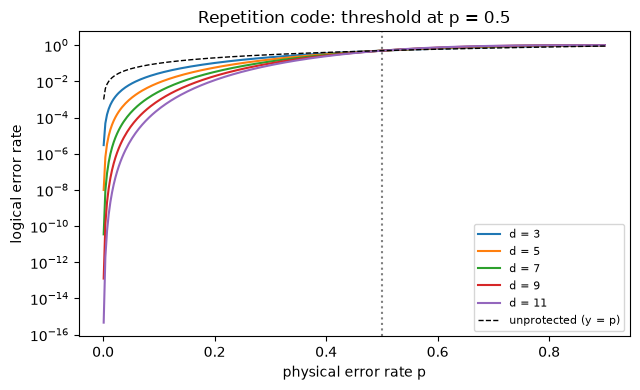

p = 5%: d=3 -> 7.3e-03,  d=11 -> 5.8e-06


In [20]:
def repetition_logical_error(d, p):
    return sum(comb(d, k) * p**k * (1 - p)**(d - k) for k in range(d // 2 + 1, d + 1))


ps = onp.linspace(0.001, 0.9, 300)
plt.figure(figsize=(6.5, 4))
for d in (3, 5, 7, 9, 11):
    plt.semilogy(ps, [repetition_logical_error(d, p) for p in ps], label=f"d = {d}")
plt.semilogy(ps, ps, "k--", lw=1, label="unprotected (y = p)")
plt.axvline(0.5, color="gray", ls=":")
plt.xlabel("physical error rate p"); plt.ylabel("logical error rate"); plt.legend(fontsize=8)
plt.title("Repetition code: threshold at p = 0.5")
plt.tight_layout(); plt.show()
print(f"p = 5%: d=3 -> {repetition_logical_error(3, 0.05):.1e},  d=11 -> {repetition_logical_error(11, 0.05):.1e}")

Left of $p = 0.5$, every increase in $d$ lowers the logical error, faster each time. Right of it, the order flips. This 50% threshold is generous for two reasons: the repetition code only handles bit flips, and the calculation assumes that measuring the syndrome never fails. The next two sections remove those assumptions one at a time.

### 4.2 The Steane code's break-even point

The Steane $[[7,1,3]]$ code corrects any single-qubit error. With a lookup decoder we can check **all** $2^7 = 128$ patterns of $X$ errors on its 7 qubits and count which ones end in a logical error. The result is exact, with no sampling.

In [21]:
H_steane = onp.array([[0, 0, 0, 1, 1, 1, 1],
                      [0, 1, 1, 0, 0, 1, 1],
                      [1, 0, 1, 0, 1, 0, 1]])

# lookup decoder: each syndrome -> the single-qubit correction that produces it
lookup = {(0, 0, 0): onp.zeros(7, dtype=int)}
for q in range(7):
    e = onp.zeros(7, dtype=int); e[q] = 1
    lookup[tuple(H_steane @ e % 2)] = e

failures_by_weight = [0] * 8
for bits in product([0, 1], repeat=7):
    error = onp.array(bits)
    residual = (error + lookup[tuple(H_steane @ error % 2)]) % 2
    if residual.sum() % 2 == 1:          # back in the code space with odd weight = logical X
        failures_by_weight[error.sum()] += 1

print("error weight:         ", list(range(8)))
print("patterns that fail:   ", failures_by_weight)


def steane_logical_error(p):
    return sum(n * p**w * (1 - p)**(7 - w) for w, n in enumerate(failures_by_weight))


break_even = brentq(lambda p: steane_logical_error(p) - p, 1e-3, 0.4)
p_dev = cz_err[(0, 1)]
print(f"\nbreak-even (code capacity): p = {break_even:.2%}")
print(f"at this device's CZ error p = {p_dev:.2%}: logical {steane_logical_error(p_dev):.1e} "
      f"-> {p_dev / steane_logical_error(p_dev):.0f}x better than an unprotected qubit")

error weight:          [0, 1, 2, 3, 4, 5, 6, 7]
patterns that fail:    [0, 0, 21, 7, 28, 0, 7, 1]

break-even (code capacity): p = 6.46%
at this device's CZ error p = 0.17%: logical 6.3e-05 -> 28x better than an unprotected qubit


No weight-1 pattern fails (the code corrects every single error), and the first failures appear at weight 2. Below a **6.5%** error per qubit, Steane beats an unprotected qubit, and at this device's error rate it would be many times better.

But this is a **code-capacity** number: it assumes the syndrome circuit, made of extra CNOTs and ancilla measurements, is perfect. Real syndrome circuits fail too.

### 4.3 Circuit-level reality with Stim

[Stim](https://github.com/quantumlib/Stim) simulates stabilizer circuits fast enough to sample millions of runs, and [PyMatching](https://github.com/oscarhiggott/PyMatching) decodes them. We use the **rotated surface code**, the code of today's below-threshold experiments, under two noise models:

- **Code capacity:** errors only on data qubits; syndrome extraction is perfect.
- **Circuit level:** the same error probability after every gate, reset and measurement, over $d$ rounds of syndrome extraction.

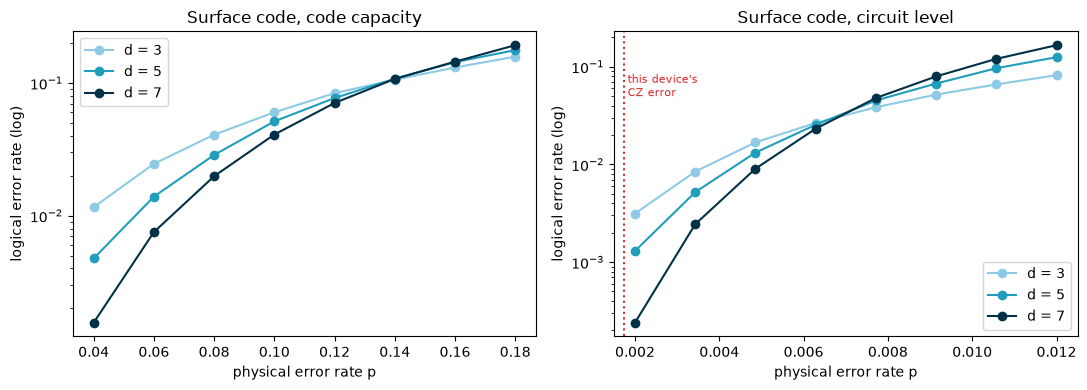

In [22]:
def surface_code_logical_error(d, p, noise="circuit", shots=50_000, seed=1):
    if noise == "circuit":
        circ = stim.Circuit.generated("surface_code:rotated_memory_z", distance=d, rounds=d,
                                      after_clifford_depolarization=p, before_round_data_depolarization=p,
                                      before_measure_flip_probability=p, after_reset_flip_probability=p)
    else:
        circ = stim.Circuit.generated("surface_code:rotated_memory_z", distance=d, rounds=1,
                                      before_round_data_depolarization=p)
    matcher = pymatching.Matching.from_detector_error_model(circ.detector_error_model(decompose_errors=True))
    detections, flips = circ.compile_detector_sampler(seed=seed).sample(shots, separate_observables=True)
    return onp.mean(matcher.decode_batch(detections)[:, 0] != flips[:, 0])


sweeps = {"code capacity": ("capacity", onp.linspace(0.04, 0.18, 8)),
          "circuit level": ("circuit", onp.linspace(0.002, 0.012, 8))}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (title, (noise, p_range)) in zip(axes, sweeps.items()):
    for d, c in zip((3, 5, 7), ("#8ecae6", "#219ebc", "#023047")):
        ax.plot(p_range, [surface_code_logical_error(d, p, noise) for p in p_range], "o-", color=c, label=f"d = {d}")
    ax.set_yscale("log"); ax.set_xlabel("physical error rate p"); ax.set_ylabel("logical error rate (log)"); ax.set_title(f"Surface code, {title}")
    ax.legend()
axes[1].axvline(p_dev, color="#d62828", ls=":"); axes[1].text(p_dev * 1.05, 0.05, "this device's\nCZ error", color="#d62828", fontsize=8)
plt.tight_layout(); plt.show()

The curves for different $d$ cross at the threshold. With perfect syndrome extraction the crossing sits near **14%**; once every gate in the syndrome circuit can fail, it drops to roughly **0.7%**, about 20 times lower. This gap between code-capacity and circuit-level thresholds is why QEC is hard: the correction machinery adds errors of its own.

How much does each step in distance help at realistic error rates? The suppression factor $\Lambda = P_L(d)/P_L(d+2)$ answers that:

In [23]:
for p in (0.001, p_dev, 0.0025):
    lep = {d: surface_code_logical_error(d, p, shots=400_000) for d in (3, 5, 7)}
    lam35 = lep[3] / max(lep[5], 1e-12)
    print(f"p = {p:.3%}:  P_L(d=3) = {lep[3]:.1e}, P_L(d=5) = {lep[5]:.1e}, P_L(d=7) = {lep[7]:.1e}   Lambda(3->5) = {lam35:.1f}")

p = 0.100%:  P_L(d=3) = 7.9e-04, P_L(d=5) = 1.1e-04, P_L(d=7) = 1.0e-05   Lambda(3->5) = 7.3


p = 0.174%:  P_L(d=3) = 2.3e-03, P_L(d=5) = 7.0e-04, P_L(d=7) = 1.3e-04   Lambda(3->5) = 3.3


p = 0.250%:  P_L(d=3) = 4.7e-03, P_L(d=5) = 1.9e-03, P_L(d=7) = 6.5e-04   Lambda(3->5) = 2.5


At this device's two-qubit error rate (0.17%), each distance step divides the logical error by about 3; at 0.25% it is about 2.5, close to the $\Lambda \approx 2.1$ that Google reported for its Willow chip (Acharya et al., 2024). At 0.1% physical error, $\Lambda$ more than doubles, to about 7. These numbers use a uniform circuit-level noise model; real devices add leakage, crosstalk and correlated errors. A small $\Lambda$ means large codes: every factor of 10 in logical error costs several distance steps, and each step adds about $4d$ physical qubits per logical qubit.

### 4.4 Why we cannot just wrap DQC in a code

Even with a good code, our circuit has a structural problem. The **Eastin–Knill theorem** says no code can implement a universal gate set transversally. Our ansatz is made of arbitrary-angle rotations $R_Y(\theta)$ and $R_X(x)$, which are exactly the gates a code cannot apply directly. A fault-tolerant computer synthesizes each one from Clifford gates and $T$ gates, and each $T$ gate consumes a distilled **magic state**.

A rough, transparent estimate of what one evaluation of $y(x)$ would cost:

In [24]:
n_rotations = 2 * n_qubits + 2 * (n_qubits - 1) * n_layers     # RX(x) twice per qubit + RY in the ansatz
eps_rotation = 1e-4                                            # synthesis accuracy per rotation
t_per_rotation = 3 * log2(1 / eps_rotation)                    # Ross-Selinger: ~3 log2(1/eps) T gates
t_count = n_rotations * t_per_rotation

p_phys = 0.001                                                 # assume 0.1% physical error (better than today)
lep_d = {d: surface_code_logical_error(d, p_phys, shots=400_000) for d in (3, 5, 7)}
lam = (lep_d[3] / lep_d[5] * lep_d[5] / max(lep_d[7], 1e-12)) ** 0.5
budget_total = 0.01                                            # allow a 1% chance that the whole run fails
logical_ops = t_count * 10                                     # rough: ~10 logical time steps per T gate
d = 3
while lep_d[3] / lam ** ((d - 3) / 2) * logical_ops * n_qubits > budget_total:
    d += 2
data_qubits = n_qubits * 2 * d**2
factory_qubits = 2 * 15 * 2 * d**2                             # two 15-to-1 distillation factories, rough

print(f"arbitrary rotations per circuit:   {n_rotations}")
print(f"T gates per circuit (eps = {eps_rotation:g}):  ~{t_count:,.0f}")
print(f"fitted Lambda at p = {p_phys:.1%}:           {lam:.1f}")
print(f"code distance needed:              d = {d}")
print(f"physical qubits, data:             ~{data_qubits:,}")
print(f"physical qubits, magic factories:  ~{factory_qubits:,}")
print(f"total:                             ~{data_qubits + factory_qubits:,} physical qubits for a 3-qubit circuit")

arbitrary rotations per circuit:   14
T gates per circuit (eps = 0.0001):  ~558
fitted Lambda at p = 0.1%:           8.9
code distance needed:              d = 11
physical qubits, data:             ~726
physical qubits, magic factories:  ~7,260
total:                             ~7,986 physical qubits for a 3-qubit circuit


This is a back-of-the-envelope estimate, not a compiled resource count, and each assumption is stated in the cell. Even so, the conclusion is robust to any reasonable change in them: a circuit that runs on **3 physical qubits** today needs about **560 $T$ gates** and **thousands of physical qubits** (about 8,000 here, 90% of them in magic-state factories) to run fault-tolerantly, even assuming hardware 1.7× better than this device. And that is for a single evaluation of $y(x)$, before training (Chapter 5). Tools such as the Azure Quantum Resource Estimator or Qualtran do this calculation properly.

<div class="alert alert-block alert-info">
<b>Check your understanding.</b> The Steane code beats an unprotected qubit below 6.5% (Section 4.2), and our device is at 0.17%. Why can't we conclude that Steane protection helps our circuit?
<details><summary>Show the answer</summary>

The 6.5% is a code-capacity break-even: it assumes perfect syndrome extraction. The syndrome circuit adds about 20 noisy two-qubit gates of its own, and a single fault inside it can cause a logical error that nothing catches. Section 4.3 shows the threshold falling about 20x once those faults are included, and Section 4.4 shows that the rotations themselves cannot be protected without magic states.

</details>
</div>

### Chapter 4 summary

- Thresholds are real and exponential suppression below them is real (4.1, 4.2).
- **Code-capacity thresholds overstate what QEC buys**: the surface code drops from ~12–16% to ~0.6–0.7% once syndrome circuits can fail.
- At today's two-qubit error rates, $\Lambda \approx 2$–3 per distance step: large codes are needed.
- **Eastin–Knill:** the arbitrary rotations at the heart of DQC require magic states. A 3-qubit circuit becomes about 8,000 physical qubits, mostly magic-state factories.

# Chapter 5 — Advantages and limitations

### 5.1 QEM versus QEC for this algorithm

| | No protection | Readout mitigation + ZNE | Error correction (surface code) |
|---|---|---|---|
| **Extra qubits** | 0 | 0 | ~2,500× (about 8,000 physical for 3 logical, Section 4.4) |
| **Extra circuits per value** | 1 | 3 | 1, but much longer |
| **Extra shots** | none | ~5× per scale, plus many more as hardware improves (3.5) | none for mitigation; continuous syndrome measurement |
| **Accuracy here** (max error vs. ideal circuit) | 2×10⁻² | 3×10⁻⁴ (3.3), with exact expectation values | arbitrarily small, below threshold |
| **Guarantee** | none | none: an *estimate* of the noiseless value, assuming the noise scales as modeled | provable suppression below threshold |
| **Scales to long circuits?** | no | no: sampling cost grows exponentially with circuit noise | yes: the only option for long computations |
| **Available today?** | yes | yes | small demonstrations only |

**Verdict for this algorithm today: readout mitigation plus ZNE.** It removes almost all of the error for no extra qubits. QEC is the right long-term answer, but not for a 3-qubit circuit on hardware where its own overhead exceeds the errors it would fix.

### 5.2 Limitations of DQC itself

Mitigation fixes the *evaluation* of a trained circuit. Training on hardware has its own costs. On a real device, every derivative comes from the parameter-shift rule, which replaces exact differentiation with extra circuit runs:

In [25]:
k = 2 * n_qubits                          # gates that carry x
circuits_y = 1
circuits_dy = 2 * k                       # one pair of shifted circuits per x-gate
circuits_d2y = (2 * k) ** 2               # naive second derivative: shift twice
per_loss = len(x_colloc) * (circuits_d2y + circuits_y) + circuits_y + circuits_dy
per_step = (2 * n_params + 1) * per_loss  # parameter-shift gradient over theta
steps, shots_per_circuit = 150, 10_000

print(f"circuits for one loss evaluation:       {per_loss:,}")
print(f"circuits for one Adam step (gradient):  {per_step:,}")
print(f"circuits for {steps} steps:                {steps * per_step:,}")
print(f"shots at {shots_per_circuit:,} per circuit:           {steps * per_step * shots_per_circuit:.1e}")
print(f"... and x 3 if every circuit is also mitigated with ZNE")

circuits for one loss evaluation:       1,173
circuits for one Adam step (gradient):  12,903
circuits for 150 steps:                1,935,450
shots at 10,000 per circuit:           1.9e+10
... and x 3 if every circuit is also mitigated with ZNE


These are naive counts (smarter shift rules and shared evaluations reduce them several-fold), but the order of magnitude stands: **training a 3-qubit DQC on hardware takes about two million circuits and 2×10¹⁰ shots.** In this tutorial we trained on a simulator and only evaluated under noise, which is the realistic workflow today.

Other limits worth knowing:

- **Shot noise in derivatives.** $y''$ is a difference of noisy estimates; its variance grows with every shift, so the loss becomes noisy before the noise model even enters.
- **Barren plateaus.** For larger, randomly initialized circuits, gradients vanish exponentially with qubit count ([McClean et al., 2018](https://doi.org/10.1038/s41467-018-07090-4)); 3 qubits avoids this, larger problems will not.
- **Expressivity is fixed by the encoding** (Section 1.2): solutions with higher frequencies need more qubits or more re-uploading.
- **Classical competition.** A 1D linear ODE is solved by classical methods in microseconds. DQC is interesting for high-dimensional, nonlinear problems, which are exactly where circuits get larger and the limits above get harder.

### 5.3 Decision guide

1. **Build the error budget** (Section 2.4). Which source dominates: readout, gates, or decoherence?
2. **Match one mitigation to each source**: readout mitigation for readout, ZNE (or PEC) for gate noise, dynamical decoupling for idle decoherence.
3. **Check the shot budget** (Section 3.5) before trusting a small improvement.
4. **Consider QEC only when** the computation is too long for mitigation's sampling cost, *and* the hardware is below the **circuit-level** threshold with enough qubits for the needed distance (Sections 4.3 and 4.4).
5. **Compare against a classical baseline** before claiming any advantage.

<div class="alert alert-block alert-info">
<b>Check your understanding.</b> Your error budget shows decoherence as the dominant source, for a deep circuit. Would ZNE by global folding still be a good first choice?
<details><summary>Show the answer</summary>

Partly. Folding does amplify idle time as well as gates, so ZNE can address decoherence, but folding a deep circuit also triples its duration, which can push the scaled values far from the linear regime. Dynamical decoupling (which shortens effective idle error without extra runs) is usually the first step, then ZNE on what remains.

</details>
</div>

# Wrap-up

In this tutorial you:

- Trained a **Differentiable Quantum Circuit** to solve $y'' + 4y = 0$ with no training data, and saw why encoding the input twice matters.
- Built a **backend-informed noise model** from `FakeMarrakesh` calibration data, cross-checked it with Qiskit Aer, and measured an **error budget**.
- Applied **ZNE** and **readout mitigation**, found that each removes a different error source, and stacked them to cut the error by about two orders of magnitude.
- Found the **folding trap**: a transpiler optimizing away your folds silently breaks ZNE.
- Computed **QEC thresholds** exactly and at circuit level, and estimated what fault tolerance would cost for this circuit.

The broader lesson is the order of operations: **measure the noise, then choose the tool**. On today's hardware and for small variational circuits, that tool is error mitigation. Error correction is what will make long, large computations possible, and Chapter 4 shows how far the overhead still is.

**Where to go next:** try a nonlinear ODE (the original DQC paper solves several), replace ZNE with probabilistic error cancellation, or run Section 2.5 on a real backend by replacing `FakeMarrakesh()` with a backend from `QiskitRuntimeService`.

# References

- Kyriienko, Paine and Elfving, "Solving nonlinear differential equations with differentiable quantum circuits," *Phys. Rev. A* 103, 052416 (2021). [arXiv:2011.10395](https://arxiv.org/abs/2011.10395)
- Pérez-Salinas et al., "Data re-uploading for a universal quantum classifier," *Quantum* 4, 226 (2020). [Link](https://quantum-journal.org/papers/q-2020-02-06-226/)
- Schuld, Sweke and Meyer, "The effect of data encoding on the expressive power of variational quantum machine learning models," *Phys. Rev. A* 103, 032430 (2021). [arXiv:2008.08605](https://arxiv.org/abs/2008.08605)
- Raissi, Perdikaris and Karniadakis, "Physics-informed neural networks," *J. Comput. Phys.* 378, 686 (2019). [DOI](https://doi.org/10.1016/j.jcp.2018.10.045)
- Temme, Bravyi and Gambetta, "Error mitigation for short-depth quantum circuits," *Phys. Rev. Lett.* 119, 180509 (2017). [arXiv:1612.02058](https://arxiv.org/abs/1612.02058)
- Giurgica-Tiron et al., "Digital zero noise extrapolation for quantum error mitigation," IEEE QCE (2020). [arXiv:2005.10921](https://arxiv.org/abs/2005.10921)
- Steane, "Error correcting codes in quantum theory," *Phys. Rev. Lett.* 77, 793 (1996).
- Fowler et al., "Surface codes: towards practical large-scale quantum computation," *Phys. Rev. A* 86, 032324 (2012). [arXiv:1208.0928](https://arxiv.org/abs/1208.0928)
- Gidney, "Stim: a fast stabilizer circuit simulator," *Quantum* 5, 497 (2021). [arXiv:2103.02202](https://arxiv.org/abs/2103.02202)
- Google Quantum AI (Acharya et al.), "Quantum error correction below the surface code threshold," *Nature* (2024). [arXiv:2408.13687](https://arxiv.org/abs/2408.13687)
- Eastin and Knill, "Restrictions on transversal encoded quantum gate sets," *Phys. Rev. Lett.* 102, 110502 (2009). [arXiv:0811.4262](https://arxiv.org/abs/0811.4262)
- Ross and Selinger, "Optimal ancilla-free Clifford+T approximation of z-rotations" (2014). [arXiv:1403.2975](https://arxiv.org/abs/1403.2975)
- McClean et al., "Barren plateaus in quantum neural network training landscapes," *Nat. Commun.* 9, 4812 (2018). [DOI](https://doi.org/10.1038/s41467-018-07090-4)
- QGSS 2026 Lab 2, "Noise, Backends, and Benchmarking in Qiskit." [GitHub](https://github.com/qiskit-community/qgss-2026/blob/main/lab-2/QGSS2026_Lab2.ipynb)

# Additional information

**Created by:** Alberto Maldonado Romo

**Version:** 1.0.0